# 1.  What is the structure and shape of the dataset?

In [5]:
import pandas as pd
df=pd.read_csv("TitanicDataset.csv")
df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
df.shape

(891, 12)

# 2. What are the data types of each column?

In [8]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

# 3. Which columns have missing values, and how can they be imputed?

In [9]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df['Age']=df['Age'].fillna(df['Age'].median())

In [11]:
df=df.drop(columns=["Cabin"])

In [13]:
df['Embarked']=df["Embarked"].fillna(df["Embarked"].mode()[0])

In [15]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

# 4.Are there any outliers (Age, Fare)? If yes, how do we treat them?

In [17]:
for col in ['Fare','Age']:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
     
# interquartile range
    IQR=Q3-Q1       
    
    Lower_limit=Q1-1.5*IQR
    Upper_limit=Q3+1.5*IQR

    Outliers=df[
        (df[col]<Lower_limit) | (df[col]>Upper_limit)
        ]

    print(col,'Outliers:',len(Outliers))
    print("Lower Limit :",Lower_limit)
    print("Upper Limit:",Upper_limit)



Fare Outliers: 116
Lower Limit : -26.724
Upper Limit: 65.6344
Age Outliers: 66
Lower Limit : 2.5
Upper Limit: 54.5


# 5.What is the overall distribution of survivors vs non-survivors?

In [18]:
Survival_counts=df["Survived"].value_counts()
Survival_counts

Survived
0    549
1    342
Name: count, dtype: int64

In [19]:
Survival_percentage=df["Survived"].value_counts(normalize=True)*100
Survival_percentage 

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

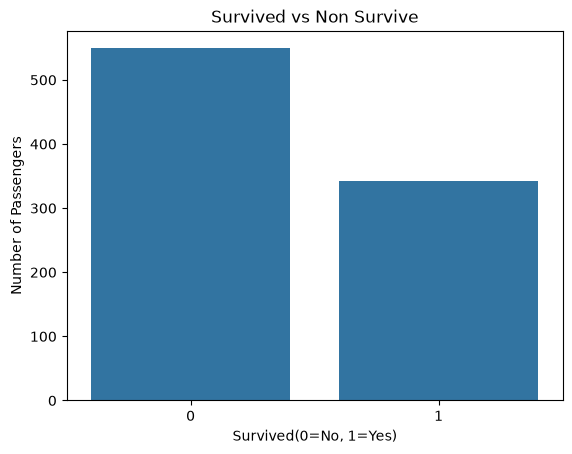

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df,x="Survived")

plt.title("Survived vs Non Survive")
plt.xlabel("Survived(0=No, 1=Yes)")
plt.ylabel("Number of Passengers")
plt.show()

# 6. How does survival differ by gender?

In [22]:
gender_survival=df.groupby("Sex")["Survived"].mean()*100
gender_survival

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

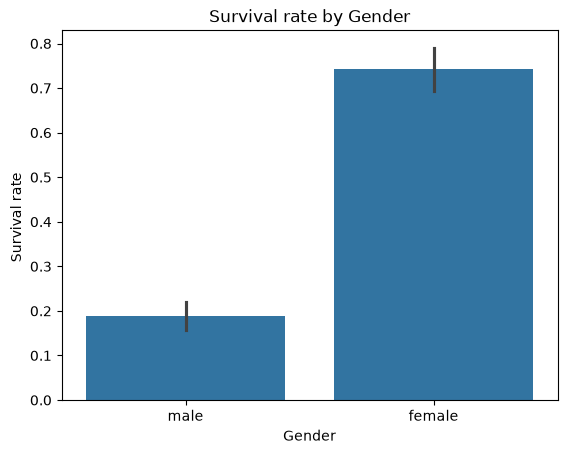

In [23]:
sns.barplot(data=df,x="Sex",y="Survived")
plt.title("Survival rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival rate ")
plt.show()

# 7.How does survival vary across passenger classes?


In [24]:
class_survival=df.groupby("Pclass")["Survived"].mean()*100
class_survival

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

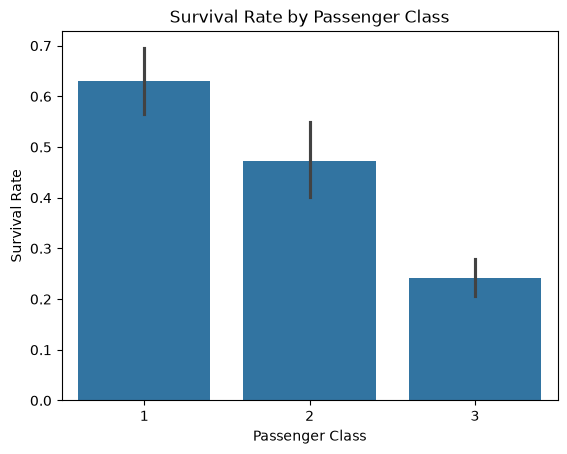

In [25]:
sns.barplot(data=df,x="Pclass",y="Survived")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

# 8.How is the Age distributed among all passengers?

In [26]:
df["Age"].describe()

count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64

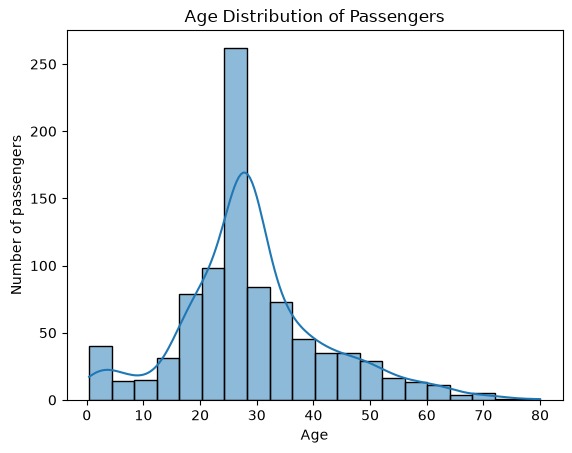

In [27]:
sns.histplot(data=df,x="Age",bins=20,kde=True)
plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.show()

# 9. Compare Age distributions between survivors and non-survivors.

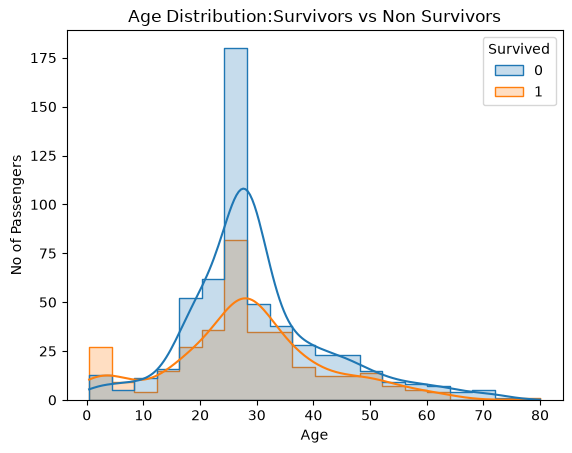

In [28]:
sns.histplot(data=df,x="Age",hue="Survived",bins=20,kde=True,element="step")
plt.title("Age Distribution:Survivors vs Non Survivors")
plt.xlabel("Age")
plt.ylabel("No of Passengers")
plt.show()

# 10. How is Ticket Fare distributed across classes

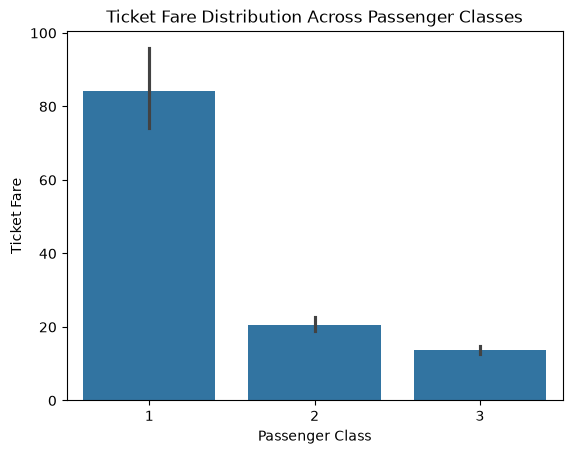

In [29]:
sns.barplot(data=df,x="Pclass",y="Fare")
plt.title("Ticket Fare Distribution Across Passenger Classes")
plt.xlabel("Passenger Class")
plt.ylabel("Ticket Fare")
plt.show()

# 11.Which port had more passengers? (Embarked distribution)

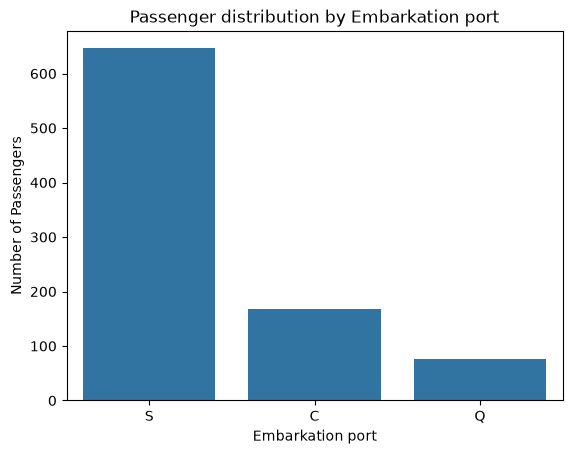

In [30]:
sns.countplot(data=df,x="Embarked")
plt.title("Passenger distribution by Embarkation port")
plt.xlabel("Embarkation port")
plt.ylabel("Number of Passengers")
plt.show()

# 12.What is the correlation among numerical variables? (Heatmap)

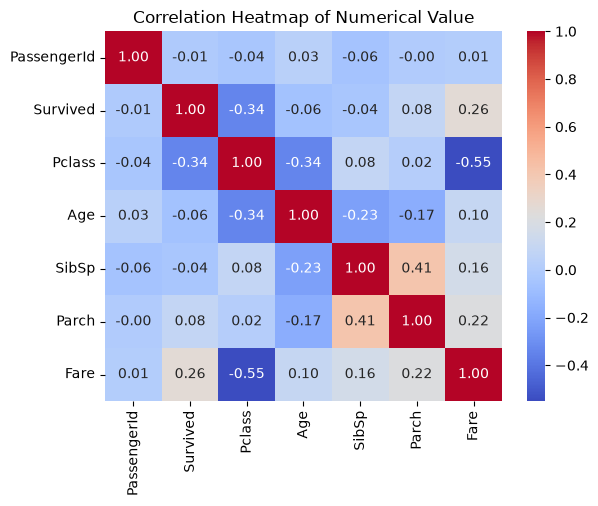

In [31]:
correletaion=df.corr(numeric_only=True)
sns.heatmap(correletaion,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap of Numerical Value")
plt.show()

# 13.Create a Family Size feature and analyze survival impact.

In [32]:
df["FamilySize"]=df["SibSp"]+df["Parch"]+1
df[["SibSp","Parch","FamilySize","Survived"]].head()

,SibSp,Parch,FamilySize,Survived
0,1,0,2,0
1,1,0,2,1
2,0,0,1,1
3,1,0,2,1
4,0,0,1,0


In [33]:
Survival_by_Family=df.groupby("FamilySize")["Survived"].mean()*100
Survival_by_Family

FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64

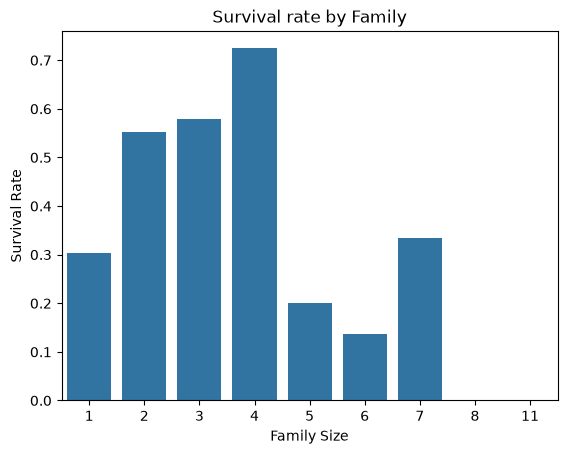

In [34]:
sns.barplot(data=df,x="FamilySize",y="Survived",errorbar=None)
plt.title("Survival rate by Family")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")
plt.show()

# 14. Create an IsAlone feature and analyze survival impact.


In [36]:
df["IsAlone"]=(df["FamilySize"]==1).astype(int)
df[["FamilySize","IsAlone","Survived"]].head(10)

,FamilySize,IsAlone,Survived
0,2,0,0
1,2,0,1
2,1,1,1
3,2,0,1
4,1,1,0
5,1,1,0
6,1,1,0
7,5,0,0
8,3,0,1
9,2,0,1


In [ ]:
Survival_Alone=df.groupby("IsAlone")["Survived"].mean()*100
Survival_Alone

# 0= Passenger Travelled with Family  and 1=Passenger travelled alone

IsAlone
0    50.564972
1    30.353818
Name: Survived, dtype: float64

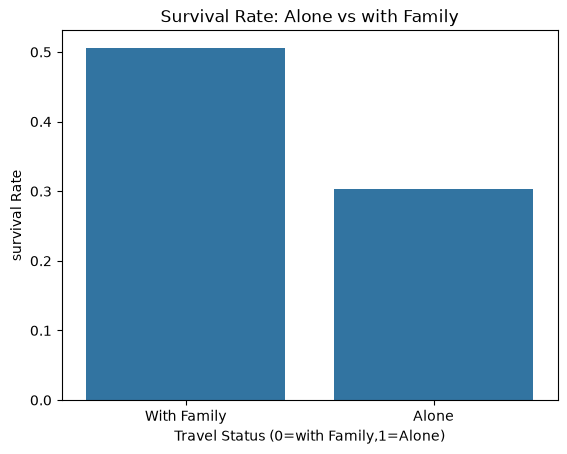

In [39]:
sns.barplot(data=df,x="IsAlone",y="Survived",errorbar=None)
plt.title("Survival Rate: Alone vs with Family")
plt.xlabel("Travel Status (0=with Family,1=Alone)")
plt.ylabel("survival Rate")
plt.xticks([0,1],["With Family","Alone"])
plt.show()

# 15.Extract Title from Name and analyze survival differences.


In [41]:
df["Title"]=df["Name"].str.extract(r",\s*([A-Za-z]+)\.",expand=False)
df[["Name","Title"]].head(10)

,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr
5,"Moran, Mr. James",Mr
6,"McCarthy, Mr. Timothy J",Mr
7,"Palsson, Master. Gosta Leonard",Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [42]:
df["Title"].value_counts()

Title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Major         2
Mlle          2
Col           2
Don           1
Mme           1
Ms            1
Lady          1
Sir           1
Capt          1
Jonkheer      1
Name: count, dtype: int64

In [43]:
survival_by_title=df.groupby("Title")["Survived"].mean()*100
survival_by_title.sort_values(ascending=False)

Title
Lady        100.000000
Sir         100.000000
Mme         100.000000
Mlle        100.000000
Ms          100.000000
Mrs          79.200000
Miss         69.780220
Master       57.500000
Major        50.000000
Col          50.000000
Dr           42.857143
Mr           15.667311
Jonkheer      0.000000
Don           0.000000
Capt          0.000000
Rev           0.000000
Name: Survived, dtype: float64

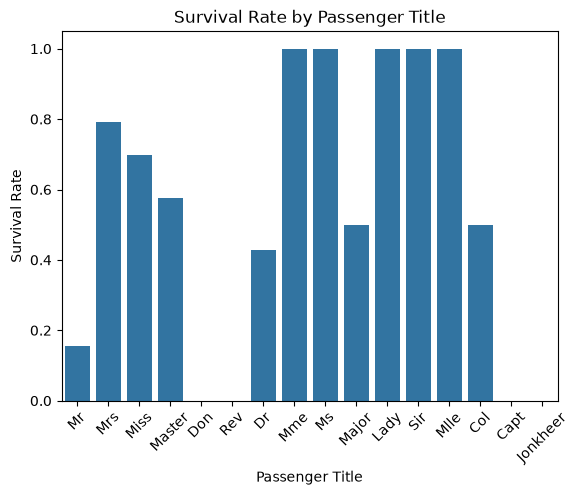

In [44]:
sns.barplot(data=df,x="Title",y="Survived",errorbar=None)
plt.title("Survival Rate by Passenger Title")
plt.xlabel("Passenger Title")
plt.ylabel("Survival Rate")
plt.xticks(rotation=45)
plt.show()

# 16. Group passengers into Age categories and analyze survival.

In [51]:
df["AgeGroup"]=pd.cut(df["Age"],bins=[0,12,19,59,float("inf")],labels=["Child","Teenager","Adult","Senior"])
df[["Age","AgeGroup"]].head(10)

,Age,AgeGroup
0,22.0,Adult
1,38.0,Adult
2,26.0,Adult
3,35.0,Adult
4,35.0,Adult
5,28.0,Adult
6,54.0,Adult
7,2.0,Child
8,27.0,Adult
9,14.0,Teenager


In [52]:
df["AgeGroup"].value_counts()

AgeGroup
Adult       701
Teenager     95
Child        69
Senior       26
Name: count, dtype: int64

In [53]:
survival_by_age=df.groupby("AgeGroup",observed=True)["Survived"].mean()*100
survival_by_age

AgeGroup
Child       57.971014
Teenager    41.052632
Adult       36.519258
Senior      26.923077
Name: Survived, dtype: float64

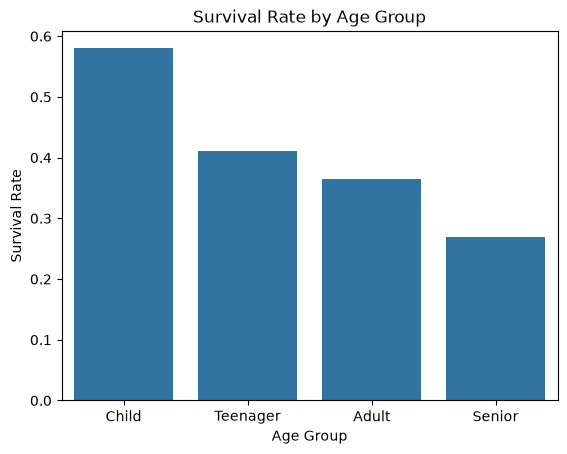

In [ ]:
sns.barplot(data=df, x="AgeGroup",y="Survived",errorbar=None)
plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.show()

In [ ]:
df.to_csv("Titanic_PowerBi.csv",index=False)